# Exploration des données climatiques : les 4 villes

## objectif:

Comparer le climat d'Abidjan, Bouaké, Korhogo et Yamoussoukro pour comprendre les saisons, les différences entre le sud et le nord, et choisir les variables à garder pour les indicateurs.

# 1. Chargement des 4 villes

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

On charge les 4 fichiers nettoyés (`power_[ville]_clean.parquet`).
On ajoute une colonne `ville` pour savoir à quelle ville appartient chaque ligne, puis on met tout dans **un seul tableau** (`climat`).

In [3]:
villes = ["abidjan", "bouake", "korhogo", "yamoussoukro"]
liste = []

for v in villes:
    d = pd.read_parquet(f"../data/processed/power_{v}_clean.parquet")
    d["ville"] = v
    liste.append(d)

climat = pd.concat(liste, ignore_index=True)
climat.shape

(65744, 22)

Résultat attendu : **65744 lignes** = 4 villes x 16436 jours (1981 à 2025).

On transforme `date` en vrai format date et on crée une colonne `mois` (1 à 12). On en aura besoin pour voir les saisons.

In [4]:
climat["date"] = pd.to_datetime(climat["date"])
climat["mois"] = climat["date"].dt.month
climat.head()

,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,QV2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,...,PS,TS,EVLAND,EVPTRNS,GWETTOP,GWETROOT,GWETPROF,date,ville,mois
0,1981,1,26.57,32.35,21.84,18.46,64.32,13.40,0.07,NaN,...,100.46,26.81,2.84,2.74,0.40,0.43,0.44,1981-01-01,abidjan,1
1,1981,2,26.82,31.59,22.89,21.43,74.24,15.99,0.12,NaN,...,100.45,27.61,2.35,2.52,0.40,0.42,0.43,1981-01-02,abidjan,1
2,1981,3,26.93,32.08,23.02,20.68,71.16,15.31,0.16,NaN,...,100.49,27.62,2.52,2.59,0.39,0.42,0.43,1981-01-03,abidjan,1
3,1981,4,26.57,31.73,22.00,19.46,67.57,14.24,0.11,NaN,...,100.53,27.21,2.45,2.45,0.39,0.42,0.43,1981-01-04,abidjan,1
4,1981,5,27.19,31.58,23.76,21.01,70.49,15.57,0.06,NaN,...,100.50,27.96,2.19,2.19,0.38,0.41,0.42,1981-01-05,abidjan,1


# 2. Valeurs manquantes

Avant de tracer quoi que ce soit, on regarde s'il y a des trous dans les données.
On sait déjà que le rayonnement solaire est vide avant 1984 (limite du satellite).

In [5]:
manquants = climat.isna().sum()
manquants[manquants > 0]

ALLSKY_SFC_SW_DWN     4380
CLRSKY_SFC_SW_DWN     4380
ALLSKY_SFC_LW_DWN    10224
dtype: int64

## Ce que j'observe

valeurs manquantes dans :  
ALLSKY_SFC_SW_DWN     4380  
CLRSKY_SFC_SW_DWN     4380  
ALLSKY_SFC_LW_DWN    10224


# 3. Comparaison des 4 villes (moyennes)

On calcule la moyenne de quelques variables importantes pour chaque ville.

La littérature agronomique identifie principalement la température, l'eau disponible, l'humidité et le rayonnement solaire comme les facteurs environnementaux majeurs influençant la croissance des plantes.

Sur cette base, les variables les plus pertinentes du dataset sont :

T2M, T2M_MAX, T2M_MIN  
PRECTOTCORR  
GWETROOT 
RH2M  
ALLSKY_SFC_SW_DWN  
EVLAND, EVPTRNS  
Ces variables seront privilégiées pour le calcul des indicateurs climatiques destinés à la recommandation de cultures.

src = "www.conservons-notre-jardin.fr" : https://www.conservons-notre-jardin.fr/regles-de-botanique/parametres-influants-sur-la-croissance/

In [6]:
variables = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR", "RH2M", "GWETROOT"]
climat.groupby("ville")[variables].mean()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,GWETROOT
ville,,,,,,
abidjan,26.232105,29.652486,23.799901,3.994118,83.009983,0.517670
bouake,26.256383,31.387670,21.881142,3.788955,74.281045,0.520904
korhogo,26.627731,32.917820,21.203968,2.815849,62.587336,0.492115
yamoussoukro,26.545337,31.764724,22.234654,3.480229,75.053946,0.539298


## Ce que j'observe

(à écrire : quelle ville est la plus chaude ? la plus humide ? la plus sèche ?)

# 4. la pluie moyenne par mois

Les graphiques sur 45 ans jour par jour sont trop chargés pour voir les saisons.
On calcule donc la **pluie moyenne de chaque mois** (janvier à décembre) pour chaque ville.
On cherche combien de pics de pluie il y a dans l'année : **un pic = une saison des pluies**, **deux pics = deux saisons**.

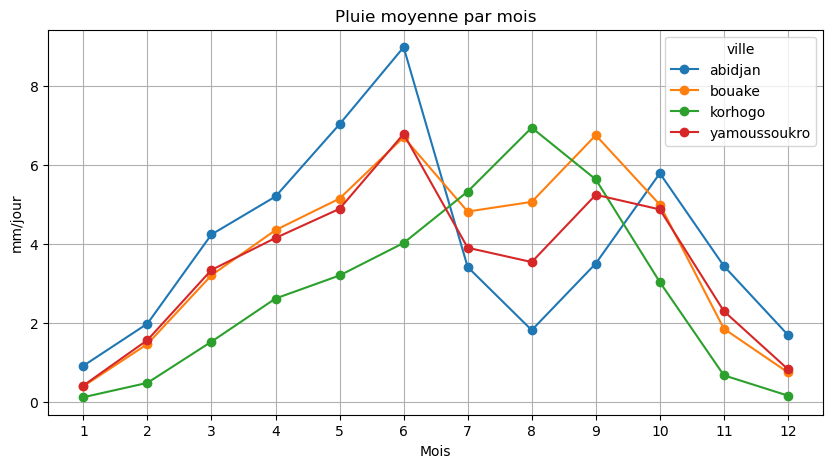

In [7]:
pluie_mois = climat.groupby(["mois", "ville"])["PRECTOTCORR"].mean().unstack()

pluie_mois.plot(figsize=(10,5), marker="o")
plt.title("Pluie moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("mm/jour")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

## Ce que j'observe

Les précipitations augmentent progressivement de janvier à juin dans la plupart des villes. Abidjan enregistre le maximum en juin (≈ 9 mm/jour), tandis que Korhogo atteint son pic en août (≈ 7 mm/jour). Après les périodes de forte pluie, les précipitations diminuent progressivement jusqu'en décembre. Globalement, Abidjan est la ville la plus pluvieuse.

# 5. Pluie totale par année

On additionne la pluie de chaque année pour chaque ville.
Cela montre les **années sèches** et les **années très pluvieuses**, et si la pluie change avec le temps.

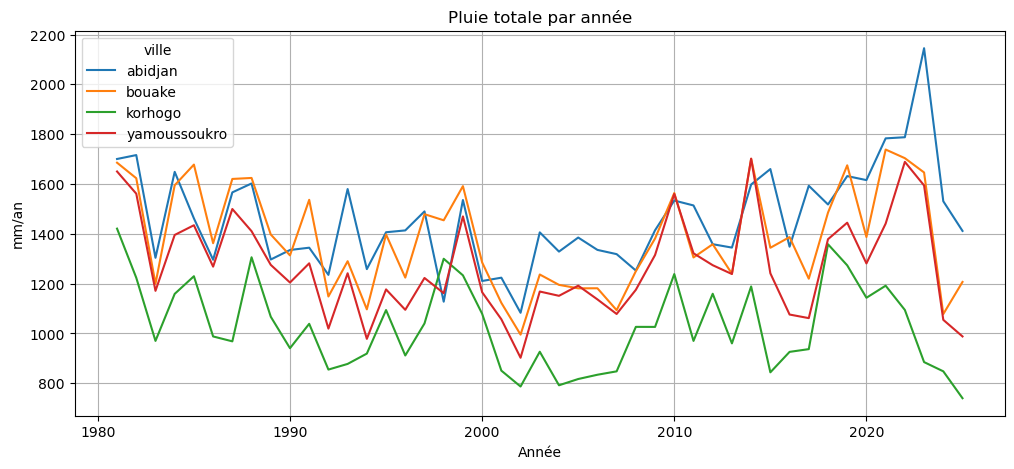

In [8]:
pluie_annee = climat.groupby(["YEAR", "ville"])["PRECTOTCORR"].sum().unstack()

pluie_annee.plot(figsize=(12,5))
plt.title("Pluie totale par année")
plt.xlabel("Année")
plt.ylabel("mm/an")
plt.grid(True)
plt.show()

## Ce que j'observe

Les précipitations annuelles varient d'une année à l'autre dans les quatre villes. Abidjan enregistre généralement les cumuls de pluie les plus élevés, avec un pic dépassant 2100 mm/an vers 2024, tandis que Korhogo est la ville la moins arrosée sur l'ensemble de la période. Bouaké et Yamoussoukro présentent des valeurs intermédiaires et suivent une évolution relativement similaire.

# 6. Les températures par mois

Même idée que pour la pluie. On regarde `T2M_MAX` (la chaleur de la journée) par mois.
C'est elle qui indique le risque de **stress de chaleur** pour les cultures.

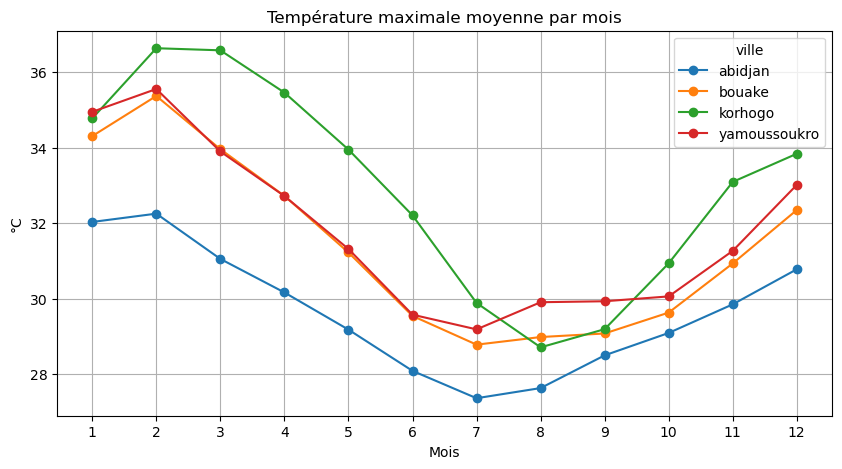

In [9]:
tmax_mois = climat.groupby(["mois", "ville"])["T2M_MAX"].mean().unstack()

tmax_mois.plot(figsize=(10,5), marker="o")
plt.title("Température maximale moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("°C")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

On regarde aussi `T2M_MIN` (les nuits).

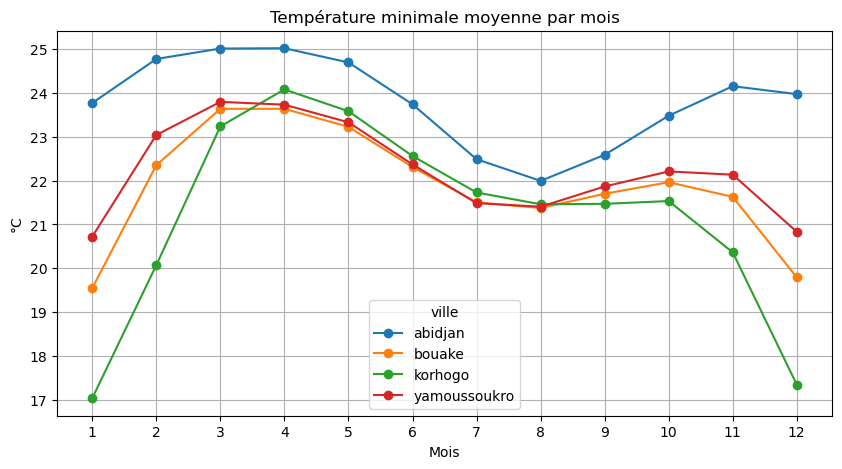

In [10]:
tmin_mois = climat.groupby(["mois", "ville"])["T2M_MIN"].mean().unstack()

tmin_mois.plot(figsize=(10,5), marker="o")
plt.title("Température minimale moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("°C")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

## Ce que j'observe

Les températures maximales et minimales diminuent globalement entre janvier et août, puis augmentent progressivement jusqu'en décembre. Korhogo enregistre les températures les plus élevées et les plus variables, tandis qu'Abidjan présente les températures les plus modérées avec de faibles écarts entre les maxima et les minima. Bouaké et Yamoussoukro affichent des comportements intermédiaires et assez similaires.

# 7. L'humidité du sol par mois

`GWETROOT` est l'humidité de la zone racinaire (entre 0 = sec et 1 = saturé).
Elle devrait suivre la pluie, avec un peu de retard. On vérifie.

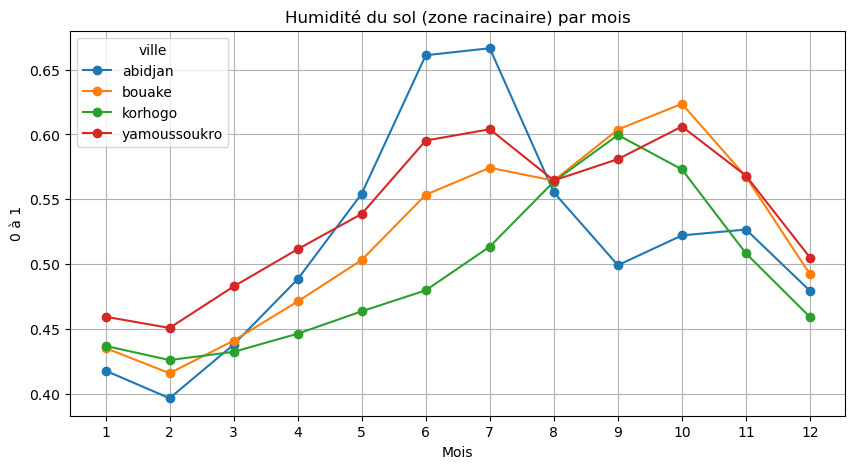

In [11]:
sol_mois = climat.groupby(["mois", "ville"])["GWETROOT"].mean().unstack()

sol_mois.plot(figsize=(10,5), marker="o")
plt.title("Humidité du sol (zone racinaire) par mois")
plt.xlabel("Mois")
plt.ylabel("0 à 1")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

## Ce que j'observe

L’humidité du sol augmente progressivement de janvier à la saison pluvieuse, puis diminue vers la fin de l’année. Abidjan présente les niveaux d’humidité les plus élevés entre juin et juillet (≈ 0,67), tandis que Bouaké, Korhogo et Yamoussoukro atteignent leurs maxima entre août et octobre. Globalement, l’évolution de l’humidité du sol suit celle des précipitations observées dans les différentes villes.

# 8. Corrélation

La corrélation mesure si deux variables bougent ensemble :
- proche de **1** : elles montent ensemble
- proche de **-1** : quand l'une monte, l'autre baisse
- proche de **0** : aucun lien

Si deux variables sont très corrélées (par exemple 0.95), elles disent presque la même chose. On pourra n'en garder qu'une.
On commence avec Abidjan.

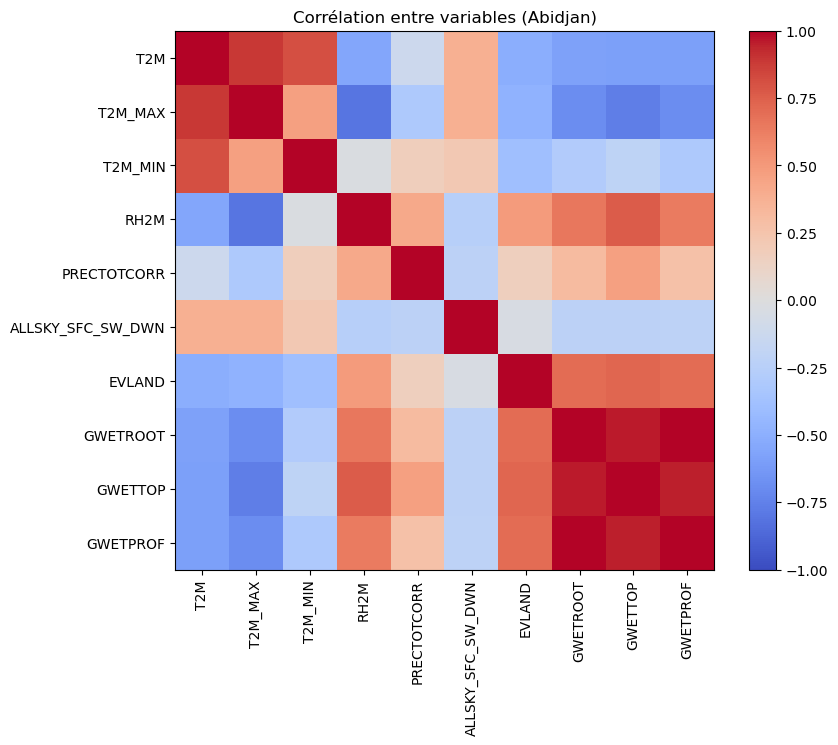

In [12]:
colonnes = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR",
            "ALLSKY_SFC_SW_DWN", "EVLAND", "GWETROOT", "GWETTOP", "GWETPROF"]

abidjan = climat[climat["ville"] == "abidjan"]
corr = abidjan[colonnes].corr()

plt.figure(figsize=(9,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(colonnes)), colonnes, rotation=90)
plt.yticks(range(len(colonnes)), colonnes)
plt.title("Corrélation entre variables (Abidjan)")
plt.show()

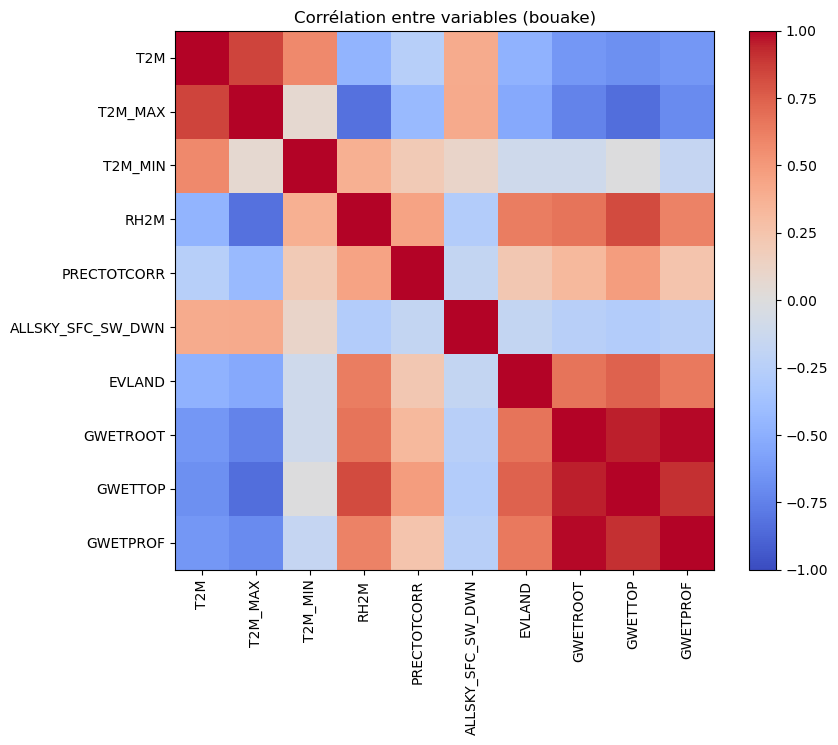

In [23]:
bouake = climat[climat["ville"] == "bouake"]
corr = bouake[colonnes].corr()

plt.figure(figsize=(9,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(colonnes)), colonnes, rotation=90)
plt.yticks(range(len(colonnes)), colonnes)
plt.title("Corrélation entre variables (bouake)")
plt.show()

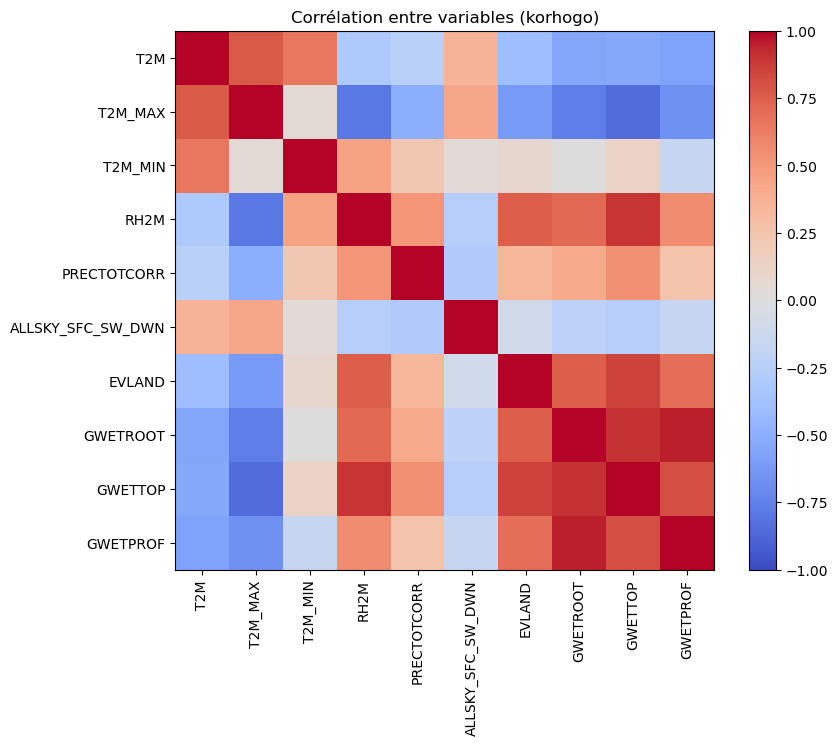

In [24]:
korhogo = climat[climat["ville"] == "korhogo"]
corr = korhogo[colonnes].corr()

plt.figure(figsize=(9,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(colonnes)), colonnes, rotation=90)
plt.yticks(range(len(colonnes)), colonnes)
plt.title("Corrélation entre variables (korhogo)")
plt.show()

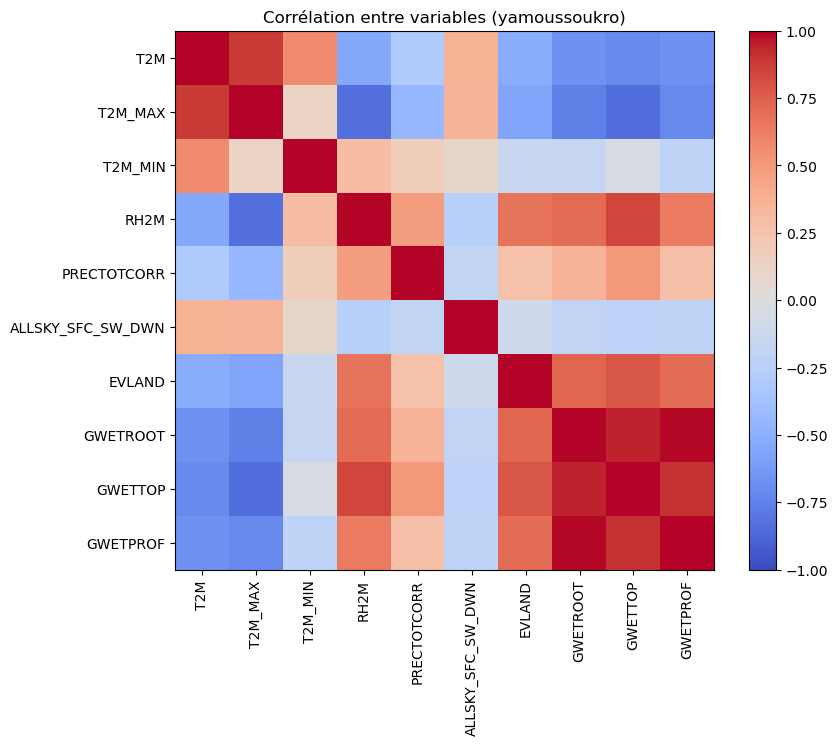

In [26]:
yamoussoukro = climat[climat["ville"] == "yamoussoukro"]
corr = yamoussoukro[colonnes].corr()

plt.figure(figsize=(9,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(colonnes)), colonnes, rotation=90)
plt.yticks(range(len(colonnes)), colonnes)
plt.title("Corrélation entre variables (yamoussoukro)")
plt.show()

In [ ]:
## correlation global
    corr = climat[colonnes].corr()
    print(corr)

                        T2M   T2M_MAX   T2M_MIN      RH2M  PRECTOTCORR  \
T2M                1.000000  0.793199  0.538208 -0.402362    -0.230689   
T2M_MAX            0.793199  1.000000 -0.065417 -0.822429    -0.416520   
T2M_MIN            0.538208 -0.065417  1.000000  0.475151     0.196933   
RH2M              -0.402362 -0.822429  0.475151  1.000000     0.427601   
PRECTOTCORR       -0.230689 -0.416520  0.196933  0.427601     1.000000   
ALLSKY_SFC_SW_DWN  0.369147  0.424206 -0.003086 -0.326827    -0.229295   
EVLAND            -0.464823 -0.564180 -0.008326  0.644717     0.256708   
GWETROOT          -0.570826 -0.664359 -0.067836  0.588340     0.343276   
GWETTOP           -0.609777 -0.805712  0.075647  0.788822     0.499459   
GWETPROF          -0.578674 -0.605654 -0.165337  0.499498     0.260096   

                   ALLSKY_SFC_SW_DWN    EVLAND  GWETROOT   GWETTOP  GWETPROF  
T2M                         0.369147 -0.464823 -0.570826 -0.609777 -0.578674  
T2M_MAX                    

# osbervation  

Analyse de corrélation : Les variables de température (T2M et T2M_MAX) sont fortement corrélées (0,79). Les variables d'humidité du sol (GWETROOT, GWETTOP et GWETPROF) sont presque identiques car elles présentent des corrélations très fortes (jusqu'à 0,98). Les précipitations (PRECTOTCORR) sont modérément liées à l'humidité de l'air (RH2M, 0,43) et à l'humidité du sol (GWETTOP, 0,50). En revanche, les précipitations sont peu liées à la température minimale (T2M_MIN, 0,20) et au rayonnement solaire (ALLSKY_SFC_SW_DWN, -0,23).

# 9. Conclusion de l'exploration


Les saisons de chaque ville :  

Abidjan : saison des pluies marquée entre mai et juillet.  
Bouaké : pluies importantes entre mai et septembre.  
Korhogo : saison des pluies plus tardive, avec un pic autour d'août.  
Yamoussoukro : régime intermédiaire avec des maxima en juin et septembre.  

Les années sèches repérées :  

Plusieurs villes présentent des déficits de pluie autour de 2002-2005 et en 2025.  
Korhogo apparaît globalement comme la ville la moins arrosée.  

Les variables à garder :  

T2M (température moyenne)  
RH2M (humidité de l'air)  
PRECTOTCORR (précipitations)  
ALLSKY_SFC_SW_DWN (rayonnement solaire)  
Une seule variable d'humidité du sol (par exemple GWETTOP)  

Les variables redondantes à retirer :  

T2M_MAX et T2M_MIN (fortement liées à T2M)  
GWETROOT et GWETPROF (très fortement corrélées à GWETTOP)  
